In [1]:
import yaml
import sys
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
import PyComplexHeatmap as pch

from matplotlib import rcParams
# Type 2/TrueType fonts
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42
# Arial font
rcParams['font.sans-serif'] = "Arial"
rcParams['font.family'] = "sans-serif"

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']  # Syntax: sym_cellline_replicate
cell_line_colors=config['cell_line_colors']

In [2]:
seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']
path = Path(config['TEMPDIR']) / 'pooled_screen_1/fastq'

# Stats of counts per guide

In [3]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts_corrected.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

In [4]:
# the lowest we ever detect any guide in Pools is 217
gmin = df.loc[:, pools].min(1).min()
df_ = df.loc[:, pools].min(1).reset_index()
df_['NT guide'] = df.index.isin(controls)

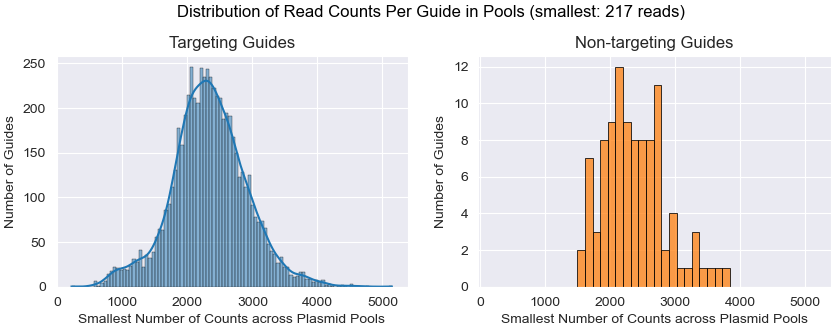

In [5]:
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(10, 3), sharex=True)
ax = axs[0]
sns.histplot(df_[~df_['NT guide']], x=0, bins=100, kde=True, color='tab:blue', label='Non-targeting Guides', ax=ax)
ax.set_xlabel('Smallest Number of Counts across Plasmid Pools')
ax.set_ylabel('Number of Guides')
ax.set_title('Targeting Guides')

ax = axs[1]
sns.histplot(df_[df_['NT guide']], x=0, bins=20, kde=False, color='tab:orange', label='Non-targeting Guides', ax=ax)
ax.set_xlabel('Smallest Number of Counts across Plasmid Pools')
ax.set_ylabel('Number of Guides')
ax.set_title(f'Non-targeting Guides')

pl.suptitle(f'Distribution of Read Counts Per Guide in Pools (smallest: {gmin} reads)', y=1.05)
pl.savefig('../results/qc_plots/hist_read_counts_per_guide_in_plasmid_pools.pdf', bbox_inches='tight')
pl.show()

In [ ]:
# Guides per gene distribution
cell_line = pd.Series({x: int(x.split('-')[1]) if 'pool' not in x else 'pool' for x in sample_names}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2][-1] if 'pool' not in x else x.split('-')[-1] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] if 'pool' not in x else 'TP0' for x in sample_names})


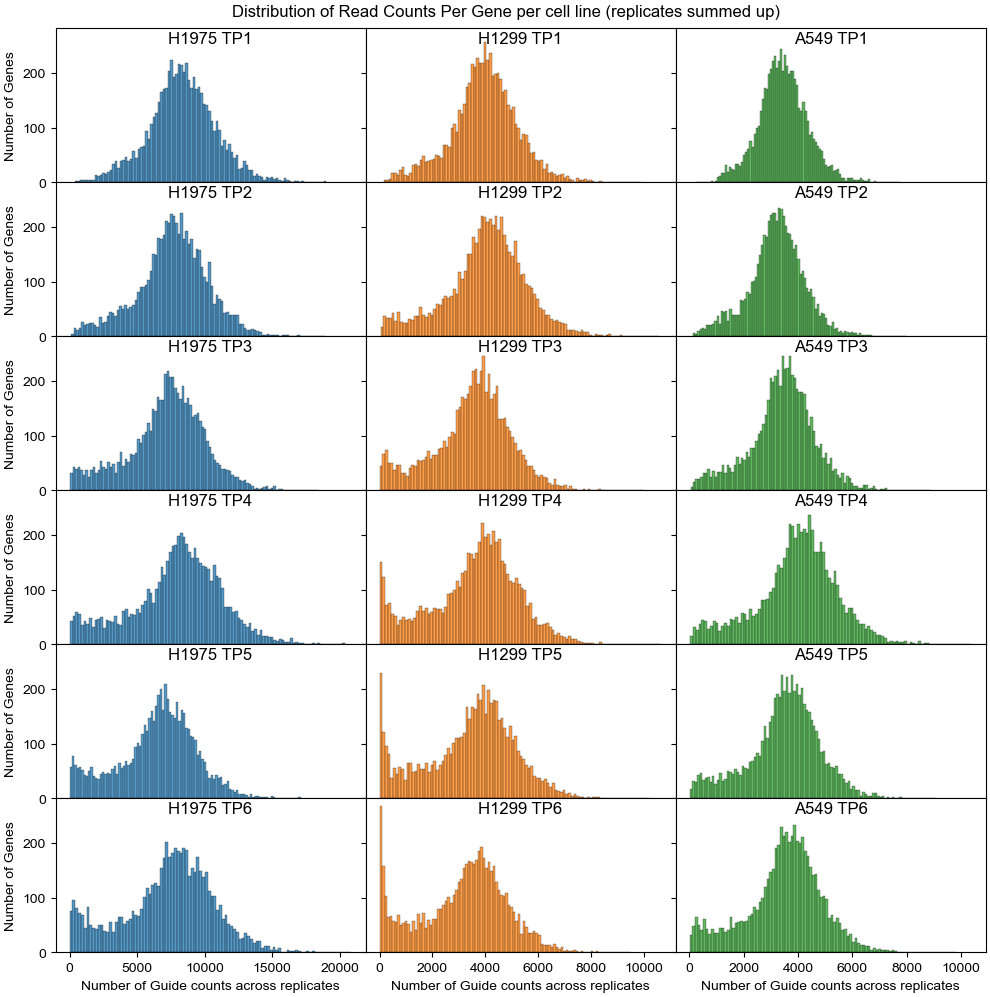

In [111]:
fig, axss = pl.subplots(6, 3, figsize=(4*3, 2*6), sharex='col', sharey=True, gridspec_kw={'hspace': 0, 'wspace': 0})
axss=axss
for i, cl in enumerate(['H1975', 'H1299', 'A549']):
    for j, tp in enumerate(['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6']):
        ax = axss[j, i]
        sample = sample_names[(time_point == tp) & (cell_line == cl)]
        df_ = df.loc[:, sample].sum(1)
        sns.histplot(df_, bins=100, color=cell_line_colors[cl], label='Non-targeting Guides', ax=ax)
        ax.set_xlabel('Number of Guide counts across replicates')
        ax.set_ylabel('Number of Genes')
        ax.set_title(f'{cl} {tp}', y=0.85)
pl.suptitle(f'Distribution of Read Counts Per Gene per cell line (replicates summed up)', y=0.90)
pl.savefig('../results/qc_plots/hist_read_counts_per_gene.pdf', bbox_inches='tight')
pl.show()

# Correlation between guides targeting the same target

In [6]:
# Load Data
df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts_corrected.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]
df['essential'] = annotate_essentiality(df.Gene)

# Normalize to NT depth
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None
l2fc['Transcript_ID'] = df.Transcript_ID.copy()
l2fc['Gene'] = df.Gene.copy()

In [16]:
l2fc.drop('Transcript_ID', axis=1).groupby('Gene').corr().mean(1).reset_index().groupby('Gene').mean('0')

,0
Gene,
AATBC,0.467428
ACKR2,0.564371
ACTA2-AS1,0.202240
ACTB,0.840836
ACTG1,0.856543
...,...
ZNF728,0.286443
ZNF93,0.350073
ZNHIT2,0.088266


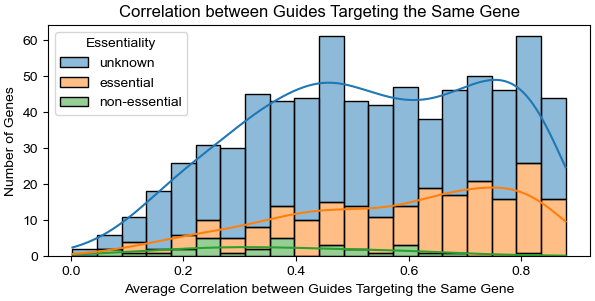

In [21]:
# Calculate the correlation between guides targeting the same gene
corr = l2fc.drop('Transcript_ID', axis=1).groupby('Gene').corr().mean(1).reset_index().groupby('Gene').mean('0')
corr['essential'] = annotate_essentiality(corr.index)
corr.rename(columns={0: 'Correlation'}, inplace=True)
fig, ax = pl.subplots(figsize=(7, 3))
sns.histplot(corr, x='Correlation', bins=20, kde=True, hue='essential', multiple="stack", ax=ax)
ax.set_xlabel('Average Correlation between Guides Targeting the Same Gene')
ax.set_ylabel('Number of Genes')
ax.set_title('Correlation between Guides Targeting the Same Gene')
ax.legend_.set_title('Essentiality')
pl.savefig('../results/qc_plots/hist_correlation_between_guides_per_gene.pdf', bbox_inches='tight')
pl.show()

# Evaluate guide counting /alignment to screen

In [40]:
alignment_qc = pd.read_csv('../results/multiqc/multiqc_data/mqc_samtools_alignment_plot_1.txt', sep='\t', index_col=0)
alignment_qc['sample_id'] = [x.split('_L00')[0] for x in alignment_qc.index ]
alignment_qc = alignment_qc.groupby('sample_id').mean()  # merge lanes
alignment_qc['cell_line'] = [x.split('-')[1] for x in alignment_qc.index ]
alignment_qc.cell_line.replace({f'0{x}': y for x, y in cell_line_dict.items()}, inplace=True)
alignment_qc['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-5] for x in alignment_qc.index ]
alignment_qc['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in alignment_qc.index ]
alignment_qc['total_reads'] = alignment_qc[['Mapped (with MQ>0)', 'MQ0', 'Unmapped']].sum(1)
alignment_qc['fraction_mapped'] = alignment_qc['Mapped (with MQ>0)'] / alignment_qc['total_reads']
alignment_qc['cell_line_x_replicate'] = [f'{x}_{y}' for x, y in zip(alignment_qc.cell_line, alignment_qc.replicate)]

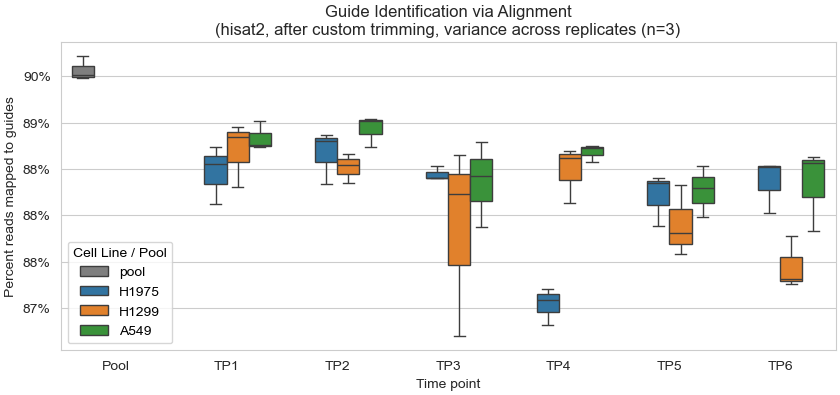

In [45]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(10,4))
sns.boxplot(data=alignment_qc.reset_index(), x='time_point', y='fraction_mapped', ax=ax, hue='cell_line', dodge=True, palette=config['cell_line_colors'])
import matplotlib.ticker as mtick
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.set_ylabel('Percent reads mapped to guides')
ax.set_xlabel('Time point')
ax.set_title('Guide Identification via Alignment\n(hisat2, after custom trimming, variance across replicates (n=3)')
pl.savefig('../results/qc_plots/qc_mapping_guide_alignment.pdf', bbox_inches='tight')
pl.legend(loc='lower left', title='Cell Line / Pool')
pl.show()

# Sample Correlation

In [4]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts_corrected.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

In [5]:
# Calculate pairwise correlations between samples
pairwise_correlations = pd.DataFrame(index=sample_names, columns=sample_names, dtype=float)
for i in sample_names:
    for j in sample_names:
        pairwise_correlations.loc[i, j] = np.corrcoef(df.loc[:, i], df.loc[:, j])[0, 1]

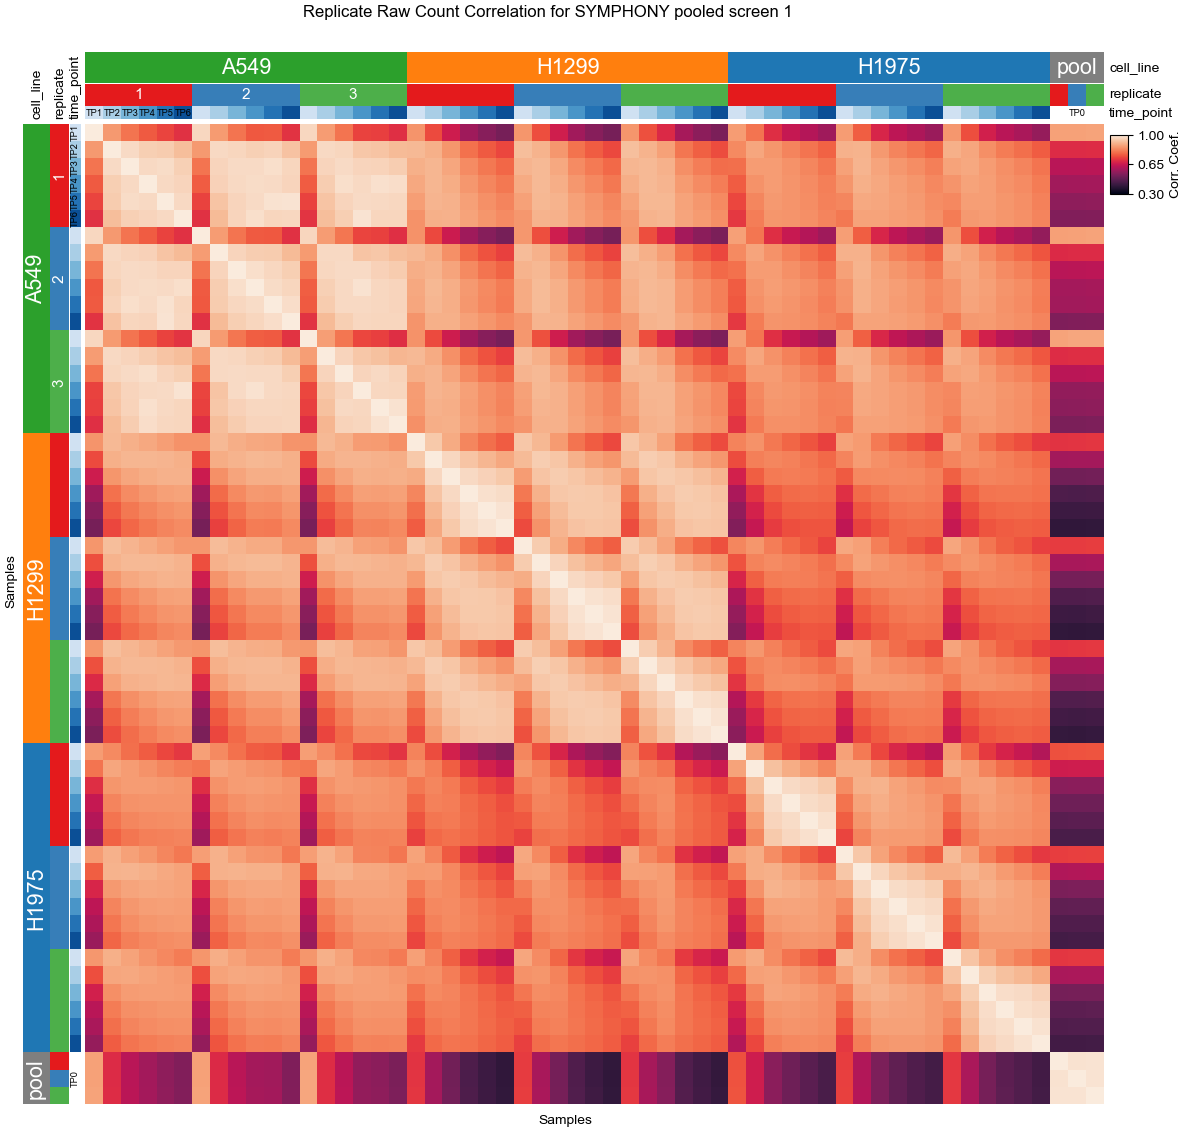

In [48]:
# Prepare annotation
cell_line = pd.Series({x: cell_line_dict[int(x.split('-')[1])] if x.split('-')[1]!='pool' else 'pool' for x in sample_names})
replicate = pd.Series({x: x.split('-')[2][-1] if 'pool' not in x else x.split('-')[-1] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] if 'pool' not in x else 'TP0' for x in sample_names})
order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 1, 2]).index  # sort by time before replicate

# select and reorder
data = pairwise_correlations.loc[order, order]

# Create the colormap
from matplotlib.colors import LinearSegmentedColormap
cmap = sns.color_palette('Blues', as_cmap=True)
colors = [cmap(x) for x in np.linspace(0.2, 0.9, 7)] + [(1, 1, 1, 1)]  # white for TP0
time_cmap = LinearSegmentedColormap.from_list("gradual_colormap", colors, N=7)

annot_kwargs = dict(
    cell_line=pch.anno_simple(cell_line.loc[order], add_text=True, height=7, colors=cell_line_colors),
    replicate=pch.anno_simple(replicate.loc[order], add_text=True, height=5),
    time_point=pch.anno_simple(time_point.loc[order], add_text=True, height=3, cmap=time_cmap),
    verbose=0, plot_legend=False
)
top_ha = pch.HeatmapAnnotation(axis=1, **annot_kwargs)
left_ha = pch.HeatmapAnnotation(axis=0, **annot_kwargs)

pl.figure(figsize=(14, 12))
cm = pch.ClusterMapPlotter(
    data=data, left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=0.3, vmax=1,
    legend_kws=dict(label='Corr. Coef.'),
    xlabel="Samples", ylabel='Samples', legend_hpad=0,
    verbose=0
)
pl.suptitle('Replicate Raw Count Correlation for SYMPHONY pooled screen 1', y=0.92)
pl.savefig('../results/qc_plots/qc_correlation_heatmap_simple.png', dpi=300)
pl.savefig('../results/qc_plots/qc_correlation_heatmap_simple.pdf', dpi=300, bbox_inches='tight')
pairwise_correlations.to_csv('../results/qc_plots/qc_correlation_source_data.csv')
pl.show()

In [29]:
# Prepare annotation
cell_line = pd.Series({x: cell_line_dict[int(x.split('-')[1])] if x.split('-')[1]!='pool' else 'pool' for x in sample_names})
replicate = pd.Series({x: x.split('-')[2][-1] if 'pool' not in x else x.split('-')[-1] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] if 'pool' not in x else 'TP0' for x in sample_names})
order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 1, 2]).index  # sort by time before replicate

# select and reorder
data = pairwise_correlations.loc[order, order]
data = data.loc[data.index.str.contains('TP6'), :].loc[:, data.columns.str.contains('TP6')]
data.index = data.index.str[:6]
data.columns = data.columns.str[:6]

In [41]:
means = []
for cell_line in data.index.str[:6].unique():
    mean_corr = np.triu(data.loc[cell_line, cell_line], 1).sum()/3
    means.append(mean_corr)
    print(f"Mean correlation for {cell_line} at TP6 across replicates: {mean_corr}")
print(f"Overall mean correlation at TP6 across replicates: {np.mean(means)}")

Mean correlation for sym-03 at TP6 across replicates: 0.9611169156282866
Mean correlation for sym-02 at TP6 across replicates: 0.929621860676118
Mean correlation for sym-01 at TP6 across replicates: 0.8374902174588273
Overall mean correlation at TP6 across replicates: 0.909409664587744


In [10]:
data

sym-03-01-TP1  sym-03-01-TP2  sym-03-01-TP3  \
Cell Line Replicate Time Point                                                
A549      1         TP1              1.000000       0.854954       0.796875   
                    TP2              0.854954       1.000000       0.969379   
                    TP3              0.796875       0.969379       1.000000   
                    TP4              0.758607       0.947041       0.966391   
                    TP5              0.726845       0.941264       0.971352   
                    TP6              0.697991       0.917180       0.948879   
          2         TP1              0.962729       0.853721       0.795591   
                    TP2              0.855262       0.966057       0.956462   
                    TP3              0.795126       0.959594       0.969036   
                    TP4              0.756332       0.949062       0.967407   
                    TP5              0.756808       0.954946       0.977714   
                    TP6              0.699331       0.923867       0.960505   
          3         TP1              0.962188       0.855949       0.796402   
                    TP2              0.857958       0.966193       0.956536   
                    TP3              0.797510       0.960957       0.969740   
                    TP4              0.725788       0.932653       0.958839   
                    TP5              0.719757       0.928003       0.956057   
                    TP6              0.693836       0.911189       0.945191   
H1299     1         TP1              0.845175       0.909553       0.893015   
                    TP2              0.735420       0.891353       0.903521   
                    TP3              0.653022       0.847032       0.876645   
                    TP4              0.578848       0.791932       0.832151   
                    TP5              0.538248       0.757564       0.802049   
                    TP6              0.512472       0.730746       0.777698   
          2         TP1              0.849100       0.916424       0.898879   
                    TP2              0.742321       0.897746       0.909432   
                    TP3              0.658766       0.850589       0.878775   
                    TP4              0.579597       0.793305       0.832747   
                    TP5              0.540448       0.759968       0.804282   
                    TP6              0.512710       0.732984       0.779606   
          3         TP1              0.847419       0.918315       0.902341   
                    TP2              0.742976       0.896732       0.908819   
                    TP3              0.684422       0.867085       0.893496   
                    TP4              0.587740       0.797791       0.838092   
                    TP5              0.547016       0.765280       0.810429   
                    TP6              0.521092       0.738292       0.785584   
H1975     1         TP1              0.858755       0.829316       0.787142   
                    TP2              0.797284       0.874504       0.859760   
                    TP3              0.691113       0.847616       0.860242   
                    TP4              0.641536       0.819943       0.842269   
                    TP5              0.611071       0.796333       0.824773   
                    TP6              0.576787       0.767583       0.800245   
          2         TP1              0.858292       0.893920       0.867854   
                    TP2              0.763103       0.896282       0.900242   
                    TP3              0.675320       0.852996       0.874183   
                    TP4              0.626117       0.820950       0.851448   
                    TP5              0.598445       0.799653       0.835562   
                    TP6              0.567978       0.773698       0.812129   
          3         TP1              0.849698       0.891967       0.869195   
   